# 02 - Model: benchmark, spatio-temporal validation, intervals, D+1, SHAP and maps

**Main validation**: whole stations held out of training (GroupKFold, 5 folds) **and** a later period (splits T1: Jul–Dec 2021 and T2: Jul 2022–Apr 2023). Random validation appears only as an optimistic reference.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
fig = lambda n: display(Image(filename=str(ROOT / 'reports/figures' / n)))
met = lambda n: pd.read_csv(ROOT / 'reports/metrics' / n)

In [2]:
b = met('benchmark_estimativa.csv'); b[['modelo','n','MAE','RMSE','R2','ganho_MAE_vs_baseline_%','acerto_faixa_IQAr','MAE_std_folds']].round(3)

,modelo,n,MAE,RMSE,R2,ganho_MAE_vs_baseline_%,acerto_faixa_IQAr,MAE_std_folds
0,LightGBM regularizado (offset IDW),7761,2.977,4.719,0.728,4.336,0.944,0.464
1,Ensemble RF + LightGBM reg. (offset IDW),7761,3.003,4.751,0.724,3.508,0.942,0.505
2,XGBoost reg. forte (offset IDW),7761,3.059,4.831,0.714,1.690,0.940,0.507
3,Krigagem ordinária,7761,3.078,4.912,0.705,1.078,0.940,0.382
4,IDW (baseline),7761,3.112,4.867,0.710,0.000,0.943,0.312
5,Random Forest (offset IDW),7761,3.137,4.913,0.705,-0.794,0.940,0.533
6,XGBoost regularizado (offset IDW),7761,3.158,4.953,0.700,-1.478,0.940,0.554
7,LightGBM (offset IDW),7761,3.254,5.044,0.689,-4.559,0.938,0.496
8,XGBoost (offset IDW),7761,3.298,5.135,0.677,-5.979,0.935,0.531
9,LightGBM (offset) sem satélite,7761,3.478,5.455,0.636,-11.762,0.930,0.546


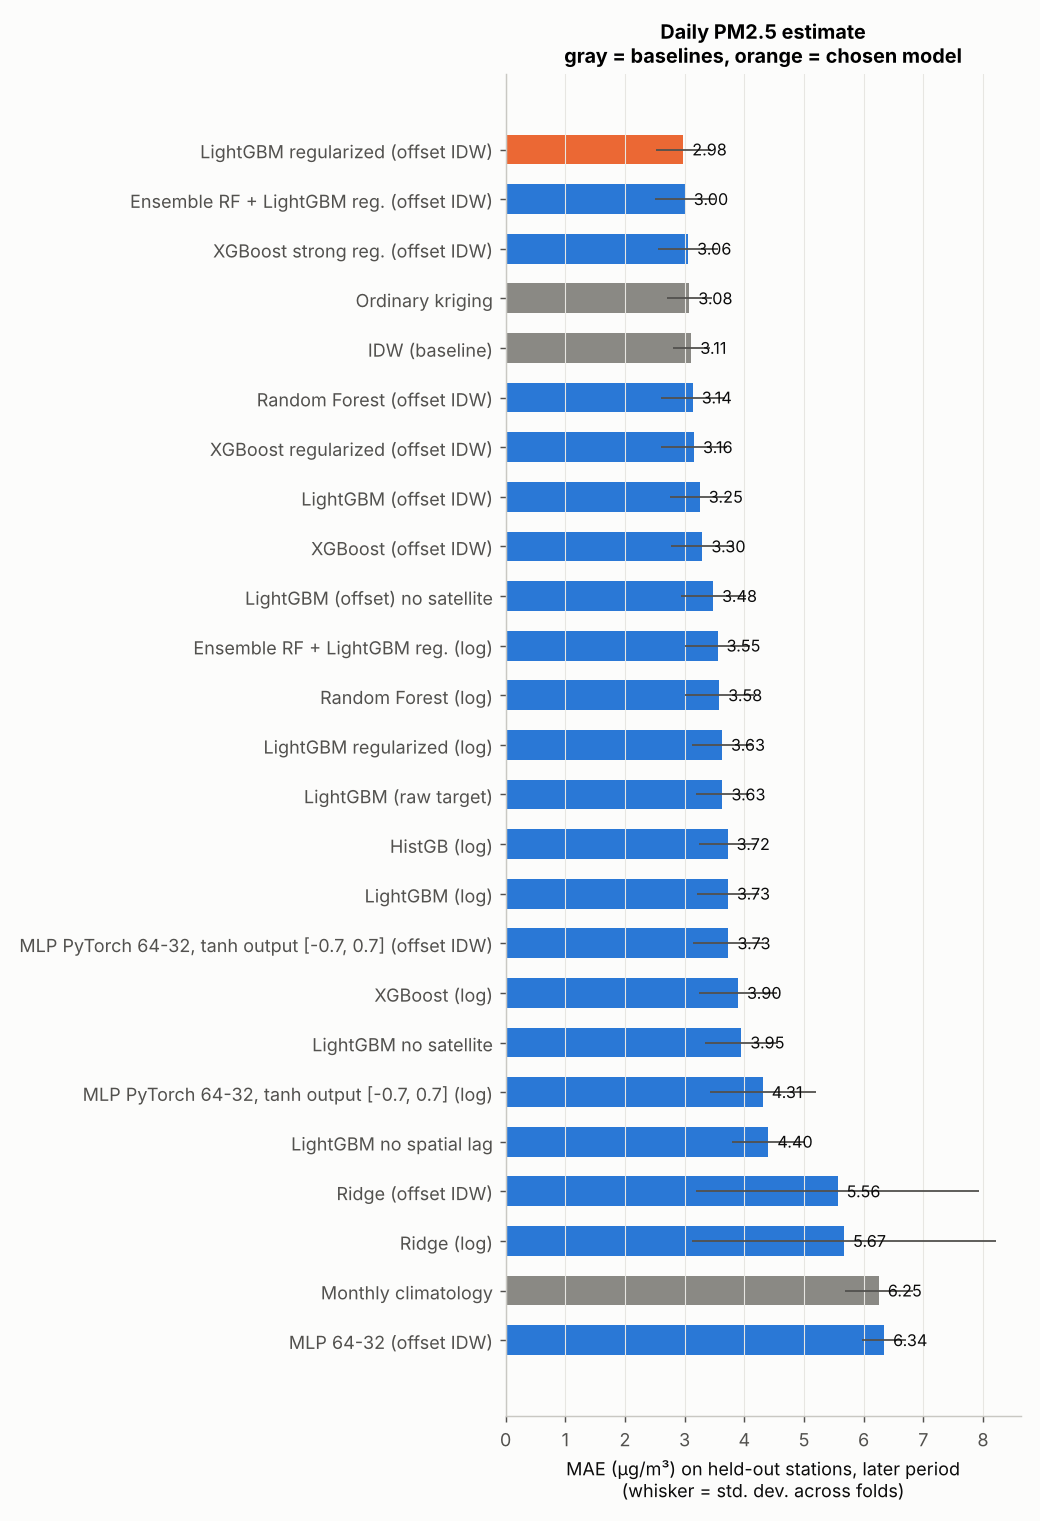

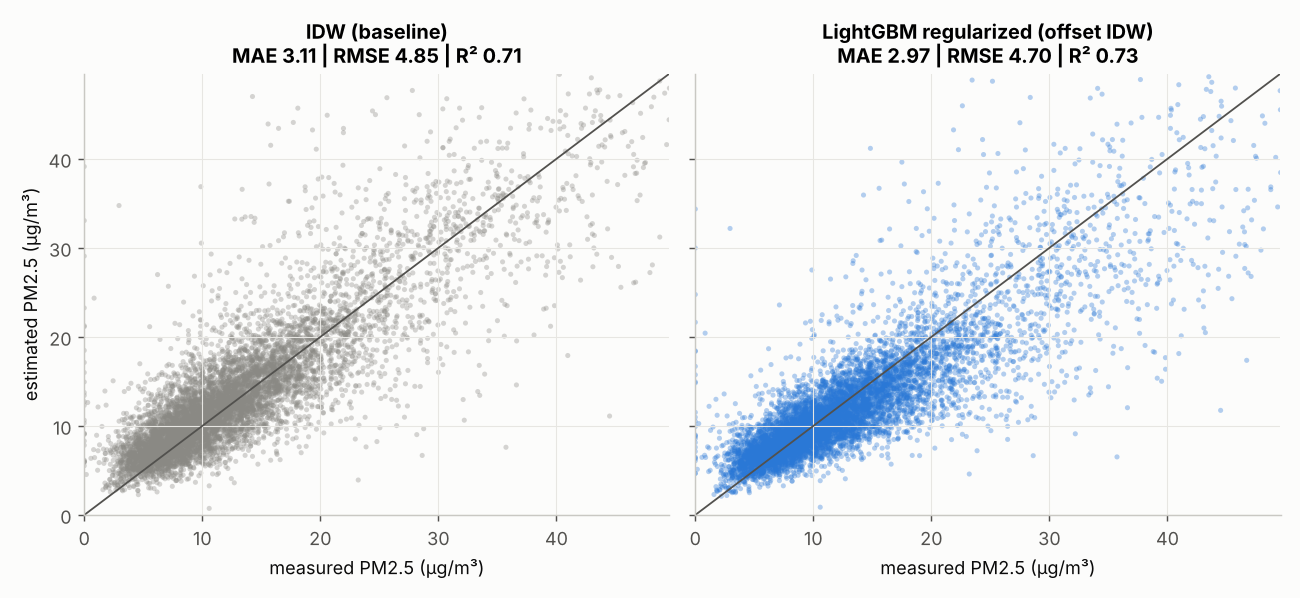

In [3]:
fig('benchmark_mae.png'); fig('dispersao_idw_vs_lgbm.png')

## Confidence interval (90%): real coverage on the test set

,recorte,metodo,n,cobertura_nominal,cobertura_real,largura_media,cobertura_pm25_>25
0,todos,Quantis LightGBM 5-95% (sem calibrar),7859,0.9,0.797,9.576,0.730
1,todos,CQR (quantis conformalizados),7859,0.9,0.906,13.485,0.836
2,todos,Conformal do resíduo absoluto,7859,0.9,0.920,14.612,0.573
3,T1,Quantis LightGBM 5-95% (sem calibrar),4102,0.9,0.814,12.234,0.753
4,T1,CQR (quantis conformalizados),4102,0.9,0.902,16.343,0.848
5,T1,Conformal do resíduo absoluto,4102,0.9,0.885,15.742,0.581
6,T2,Quantis LightGBM 5-95% (sem calibrar),3757,0.9,0.779,6.674,0.383
7,T2,CQR (quantis conformalizados),3757,0.9,0.911,10.365,0.660
8,T2,Conformal do resíduo absoluto,3757,0.9,0.958,13.379,0.447


,faixa,n,cobertura_cqr,largura_cqr
0,0-15,5471.0,0.920,9.993
1,15-25,1598.0,0.906,17.202
2,25-35,478.0,0.837,26.932
3,35-50,233.0,0.846,35.278
4,>50,52.0,0.788,44.967


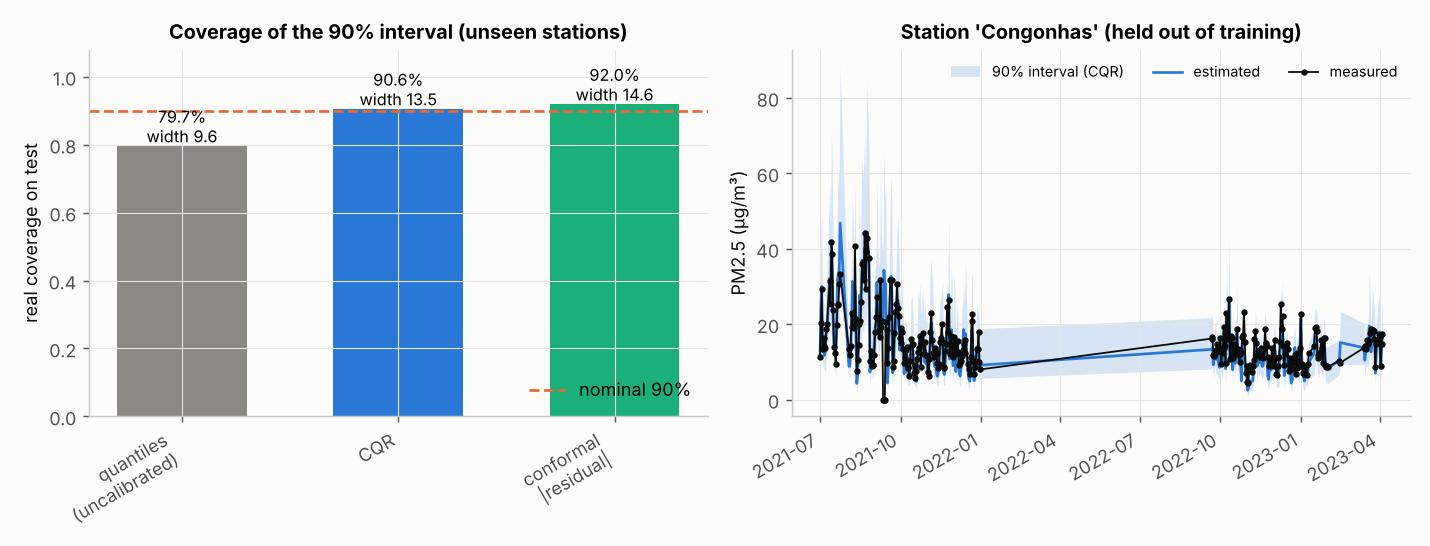

In [4]:
display(met('intervalos.csv').round(3)); display(met('intervalos_por_faixa.csv').round(3)); fig('intervalos.png')

## Next-day forecast vs. persistence

,cenario,metodo,n,MAE,RMSE,R2,acerto_faixa_IQAr,ganho_MAE_vs_baseline_%
0,A) local com estação,Persistência (amanhã = hoje),7373,4.294,6.429,0.494,0.923,NaN
1,A) local com estação,LightGBM reg. (offset IDW) D+1,7373,4.051,6.073,0.549,0.926,5.669
2,A) local com estação,Persistência (amanhã = hoje),3898,5.201,7.633,0.505,0.873,NaN
3,A) local com estação,LightGBM reg. (offset IDW) D+1,3898,5.083,7.374,0.538,0.872,2.272
4,A) local com estação,Persistência (amanhã = hoje),3475,3.277,4.728,0.083,0.978,NaN
5,A) local com estação,LightGBM reg. (offset IDW) D+1,3475,2.893,4.154,0.292,0.987,11.716
6,B) local sem estação,Persistência do IDW de hoje,7372,4.911,7.170,0.371,0.911,NaN
7,B) local sem estação,LightGBM reg. (offset IDW) D+1,7372,4.472,6.781,0.437,0.920,8.930
8,B) local sem estação,Persistência do IDW de hoje,3898,5.913,8.606,0.370,0.849,NaN
9,B) local sem estação,LightGBM reg. (offset IDW) D+1,3898,5.636,8.346,0.408,0.861,4.686


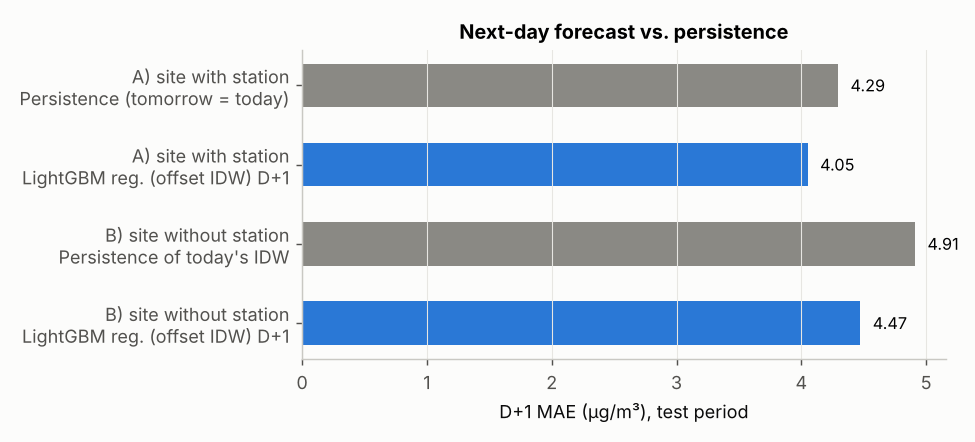

In [5]:
display(met('previsao_d1.csv')[['cenario','metodo','n','MAE','RMSE','R2','acerto_faixa_IQAr','ganho_MAE_vs_baseline_%']].round(3)); fig('previsao_d1.png')

The forecast is issued at the end of D with observations up to D and the calendar of D+1. Coverage of tomorrow's interval is measured separately, out of sample:

In [6]:
met('intervalos_d1.csv').round(3)

,cenario,recorte,n,cobertura_nominal,cobertura_real,largura_media,cobertura_pm25_>25
0,A) local com estação,todos,7373,0.9,0.882,16.282,0.779
1,A) local com estação,T1,3898,0.9,0.853,19.287,0.815
2,A) local com estação,T2,3475,0.9,0.914,12.913,0.214
3,B) local sem estação,todos,7372,0.9,0.881,18.755,0.744
4,B) local sem estação,T1,3898,0.9,0.844,21.516,0.774
5,B) local sem estação,T2,3474,0.9,0.924,15.658,0.262


## IQAr band metrics beyond raw accuracy

~90% of days are "Boa" (good): always predicting "Boa" already scores ~90%. Balanced accuracy, macro F1 and recall above 25 µg/m³ show whether polluted days are caught. The alert on the upper bound of the 90% interval is a fixed rule, not tuned on the test set.

In [7]:
display(met('faixas_iqar.csv').round(3)); met('faixas_iqar_confusao.csv')

,tarefa,metodo,n,acerto_faixa,acerto_sempre_Boa,acuracia_balanceada,f1_macro,n_obs_>25,sensibilidade_>25,precisao_>25
0,estimativa D,IDW (baseline),7761,0.943,0.902,0.489,0.487,763,0.785,0.731
1,estimativa D,Krigagem ordinária,7761,0.940,0.902,0.443,0.460,763,0.680,0.756
2,estimativa D,LightGBM regularizado (offset IDW),7761,0.944,0.902,0.444,0.476,763,0.622,0.818
3,estimativa D,Alerta: limite superior do IC 90% > 25,7859,NaN,NaN,NaN,NaN,763,0.942,0.380
4,D+1 A) local com estação,Persistência,7373,0.923,0.904,0.554,0.556,711,0.644,0.637
5,D+1 A) local com estação,LightGBM reg. (offset IDW) D+1,7373,0.926,0.904,0.344,0.375,711,0.374,0.826
6,D+1 A) local com estação,Alerta: limite superior do IC 90% > 25,7373,NaN,NaN,NaN,NaN,711,0.913,0.334
7,D+1 B) local sem estação,Persistência,7372,0.911,0.904,0.421,0.416,711,0.627,0.573
8,D+1 B) local sem estação,LightGBM reg. (offset IDW) D+1,7372,0.920,0.904,0.334,0.352,711,0.378,0.706
9,D+1 B) local sem estação,Alerta: limite superior do IC 90% > 25,7372,NaN,NaN,NaN,NaN,711,0.889,0.254


,medida,Boa,Moderada,Ruim,Muito Ruim,Péssima
0,Boa,6892,105,1,0,0
1,Moderada,281,423,7,0,0
2,Ruim,6,31,9,0,0
3,Muito Ruim,1,0,5,0,0
4,Péssima,0,0,0,0,0


## Explanation (SHAP)

,variavel,shap_medio_abs
0,idw,0.0799
1,built_5km,0.0297
2,built,0.0266
3,tree_5km,0.0239
4,prev_tp,0.0185
5,crop_5km,0.0182
6,elev,0.0157
7,doy_cos,0.0147
8,grass_5km,0.0142
9,idw_dmin,0.0142


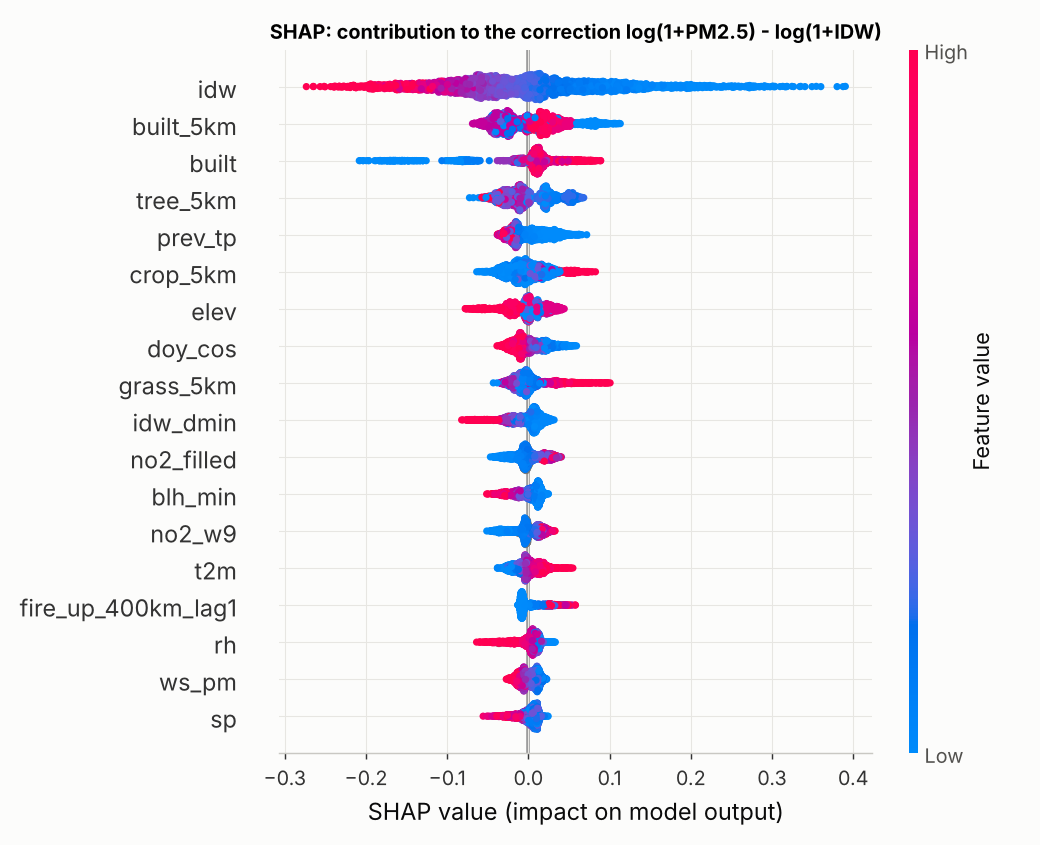

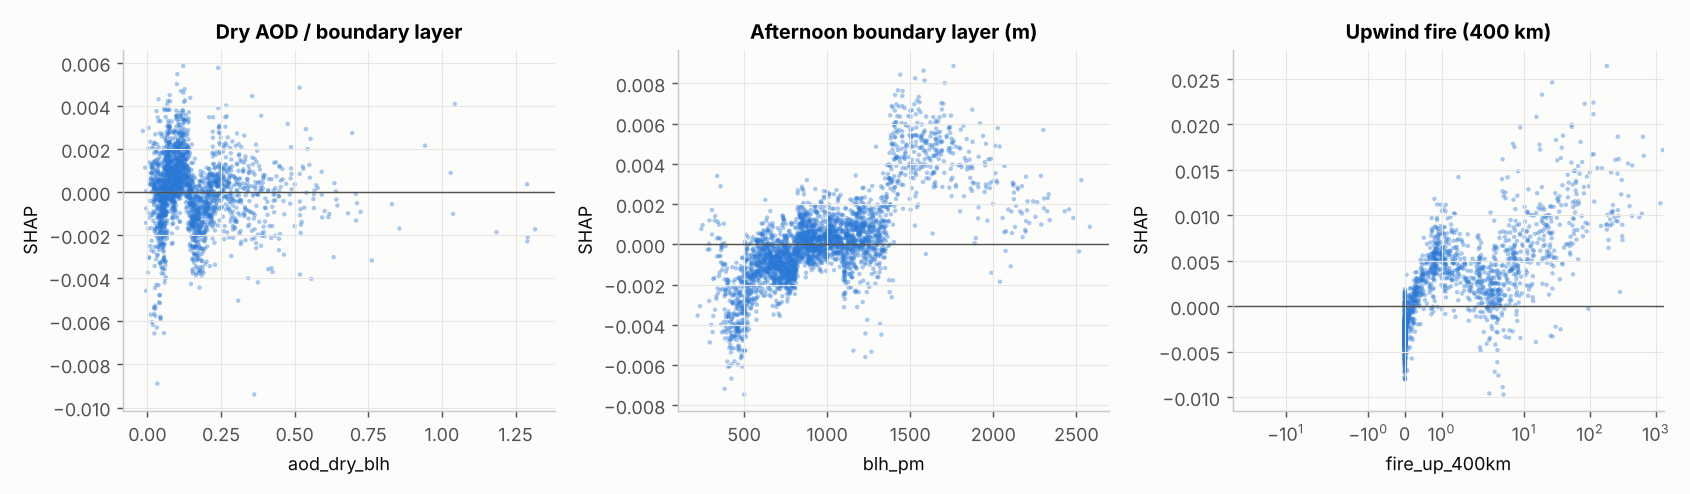

In [8]:
display(met('shap_importancia.csv').head(15).round(4)); fig('shap_resumo.png'); fig('shap_dependencia.png')

In [9]:
display(Markdown('Local example (highest predicted PM2.5 in the test sample):')); met('shap_exemplo_local.csv')

Local example (highest predicted PM2.5 in the test sample):

,Unnamed: 0,shap,valor
0,idw,-0.1923,58.4826
1,tree_5km,0.0496,0.0939
2,built,0.0474,0.7733
3,built_5km,0.0440,0.8368
4,prev_tp,0.0389,0.0000
5,crop_5km,0.0381,0.0043
6,elev,0.0341,722.8947
7,no2_filled,0.0268,143.1364
8,fire_up_400km_lag1,0.0251,170.9090
9,no2_w9,0.0247,129.3769


## Extreme episodes (smoke)

,regime,modelo,n,PM2.5_medio,MAE,vies,AOD_medio,frac_sem_AOD_obs
0,PM2.5 alto sem fogo (≥ p95),IDW (baseline),179,38.93,7.33,-5.81,0.31,0.12
1,PM2.5 alto sem fogo (≥ p95),LightGBM regularizado (offset IDW),179,38.93,9.16,-7.60,0.31,0.12
2,fumaça (fogo a favor do vento ≥ p95),IDW (baseline),393,34.32,8.03,1.31,0.27,0.10
3,fumaça (fogo a favor do vento ≥ p95),LightGBM regularizado (offset IDW),393,34.32,8.78,-3.68,0.27,0.10
4,normal,IDW (baseline),7286,11.85,2.74,0.84,0.39,0.53
5,normal,LightGBM regularizado (offset IDW),7286,11.85,2.50,-0.41,0.39,0.53


,date,pm25,pred,idw,err,fogo,aod,sem_aod
0,2021-09-14,32.90,26.56,34.36,-6.34,66.77,NaN,1.00
1,2021-09-09,22.41,17.50,22.00,-4.92,142.42,0.71,0.00
2,2021-09-19,28.80,23.97,30.15,-4.83,8.44,0.48,0.00
3,2021-09-08,34.59,30.12,36.28,-4.48,570.37,0.40,0.09
4,2021-09-21,32.36,27.95,34.72,-4.41,9.05,0.53,0.09
5,2021-09-25,22.67,18.36,23.61,-4.31,0.49,0.84,0.77
6,2021-09-26,24.03,19.77,24.44,-4.26,8.19,0.54,0.10
7,2021-08-26,37.94,33.70,38.21,-4.24,168.79,0.27,0.00
8,2021-09-10,20.16,16.00,20.17,-4.15,2.59,NaN,1.00
9,2021-09-13,27.81,23.76,28.79,-4.05,18.76,0.38,0.88


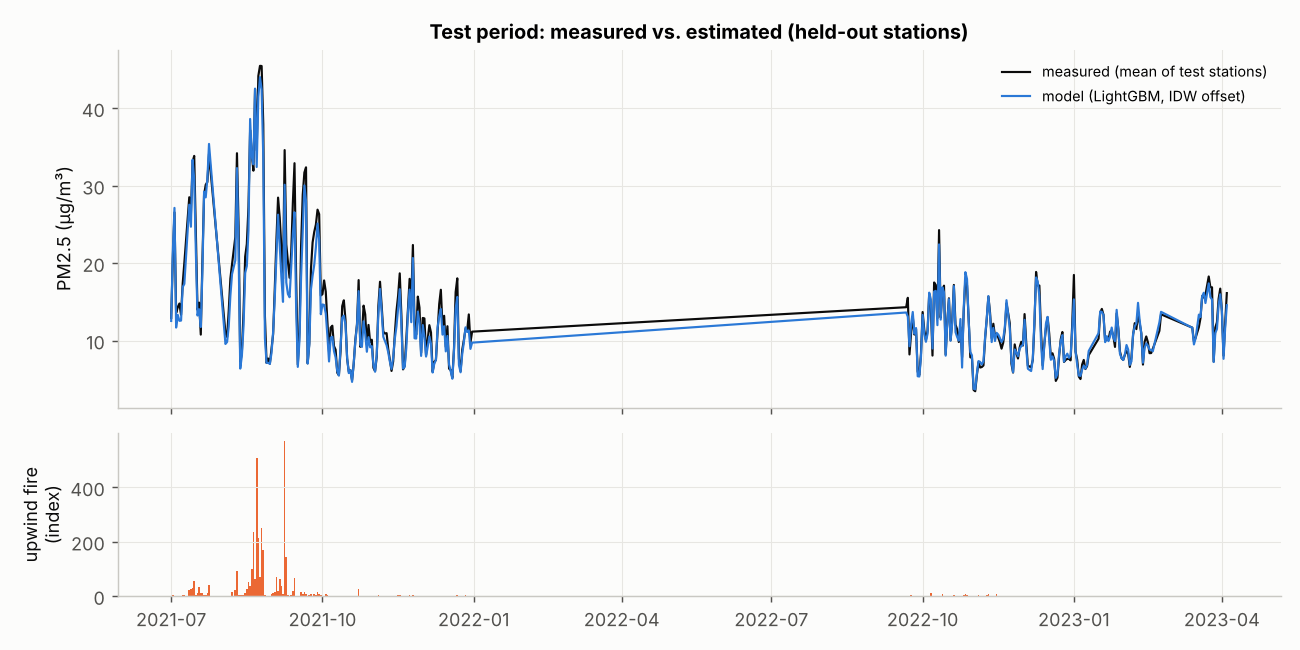

In [10]:
display(met('episodios_extremos.csv').round(2)); display(met('piores_dias.csv').head(10)); fig('episodios_serie.png')

## Daily maps (PM2.5 and uncertainty)

`mapa_pm25_2021-08-24_h0.png`

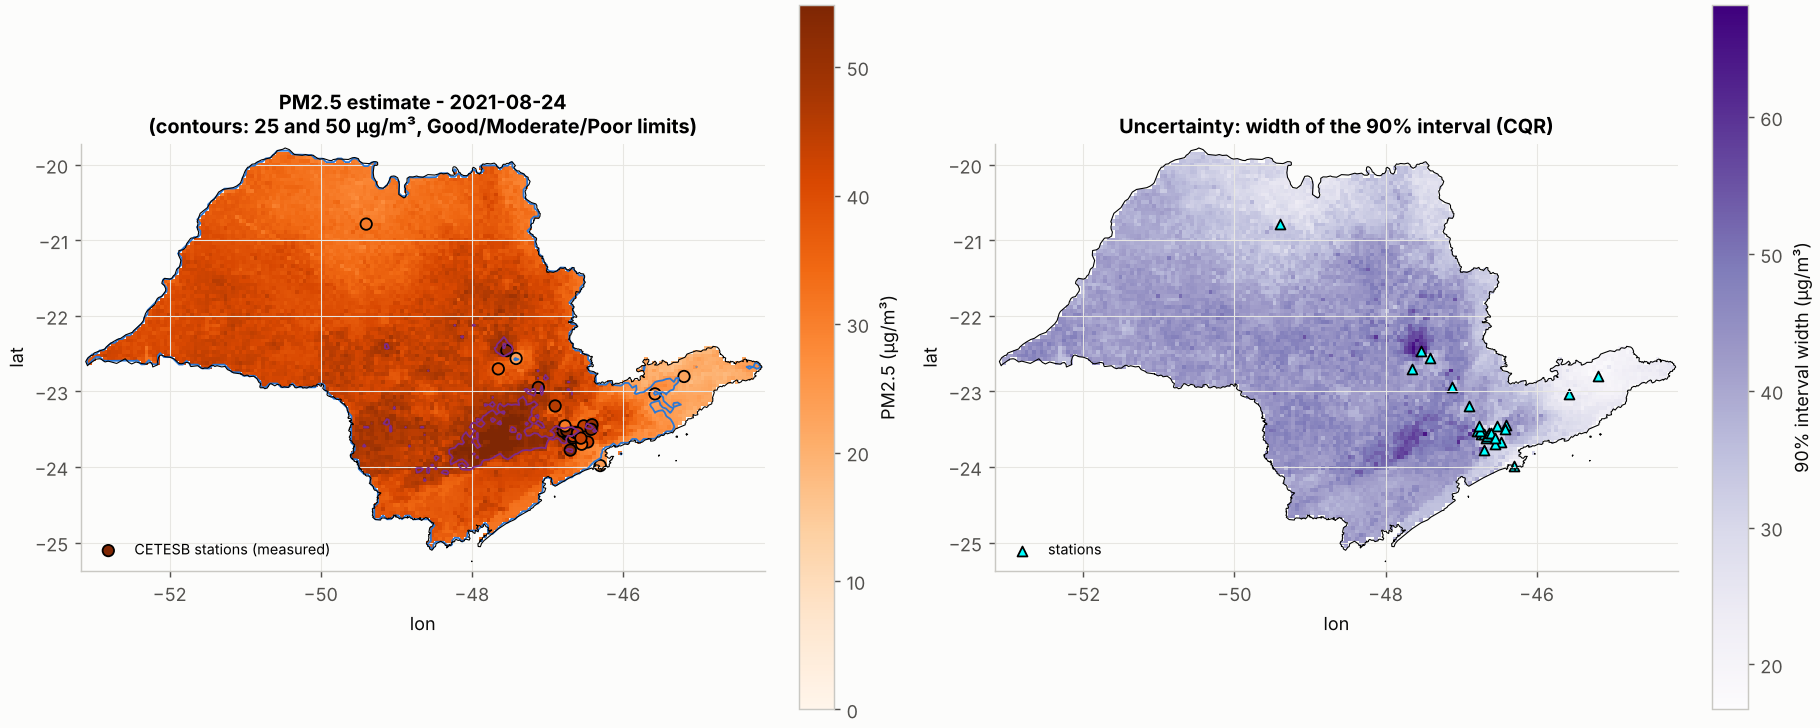

`mapa_pm25_2021-08-24_h1.png`

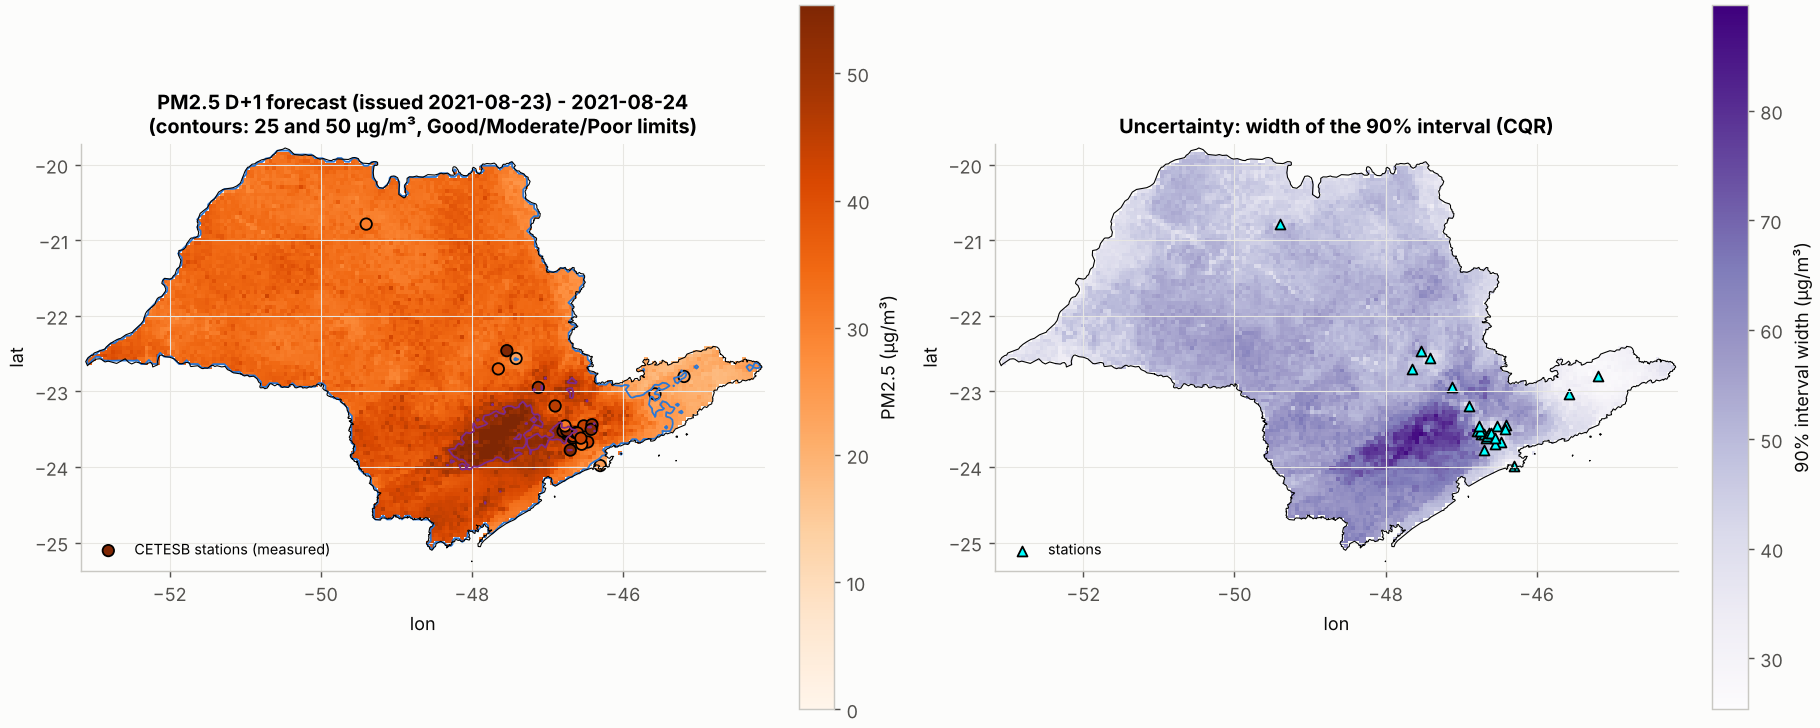

`mapa_pm25_2022-10-11_h0.png`

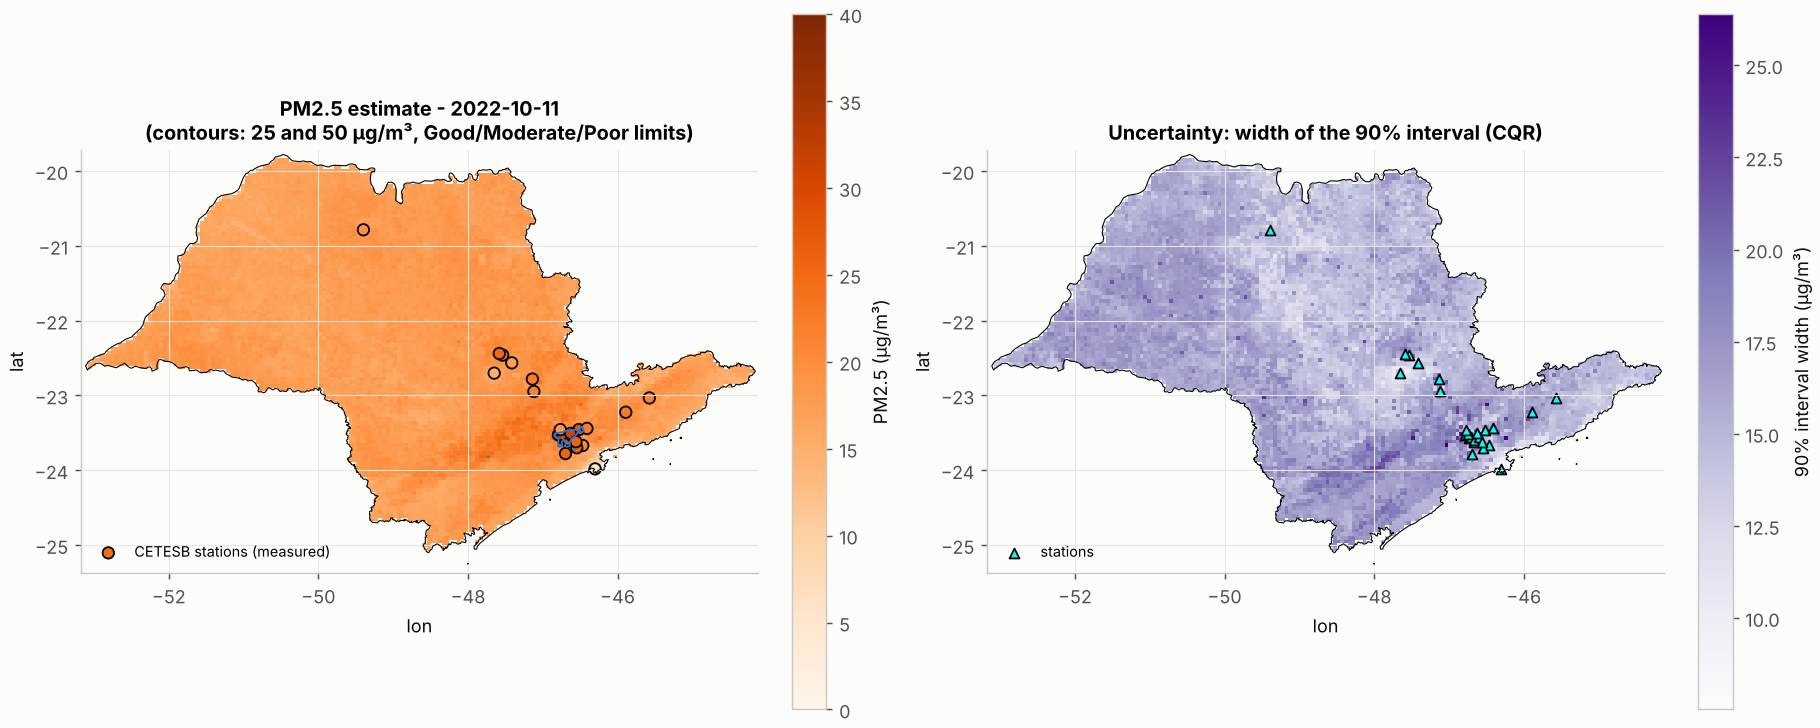

`mapa_pm25_2022-11-16_h0.png`

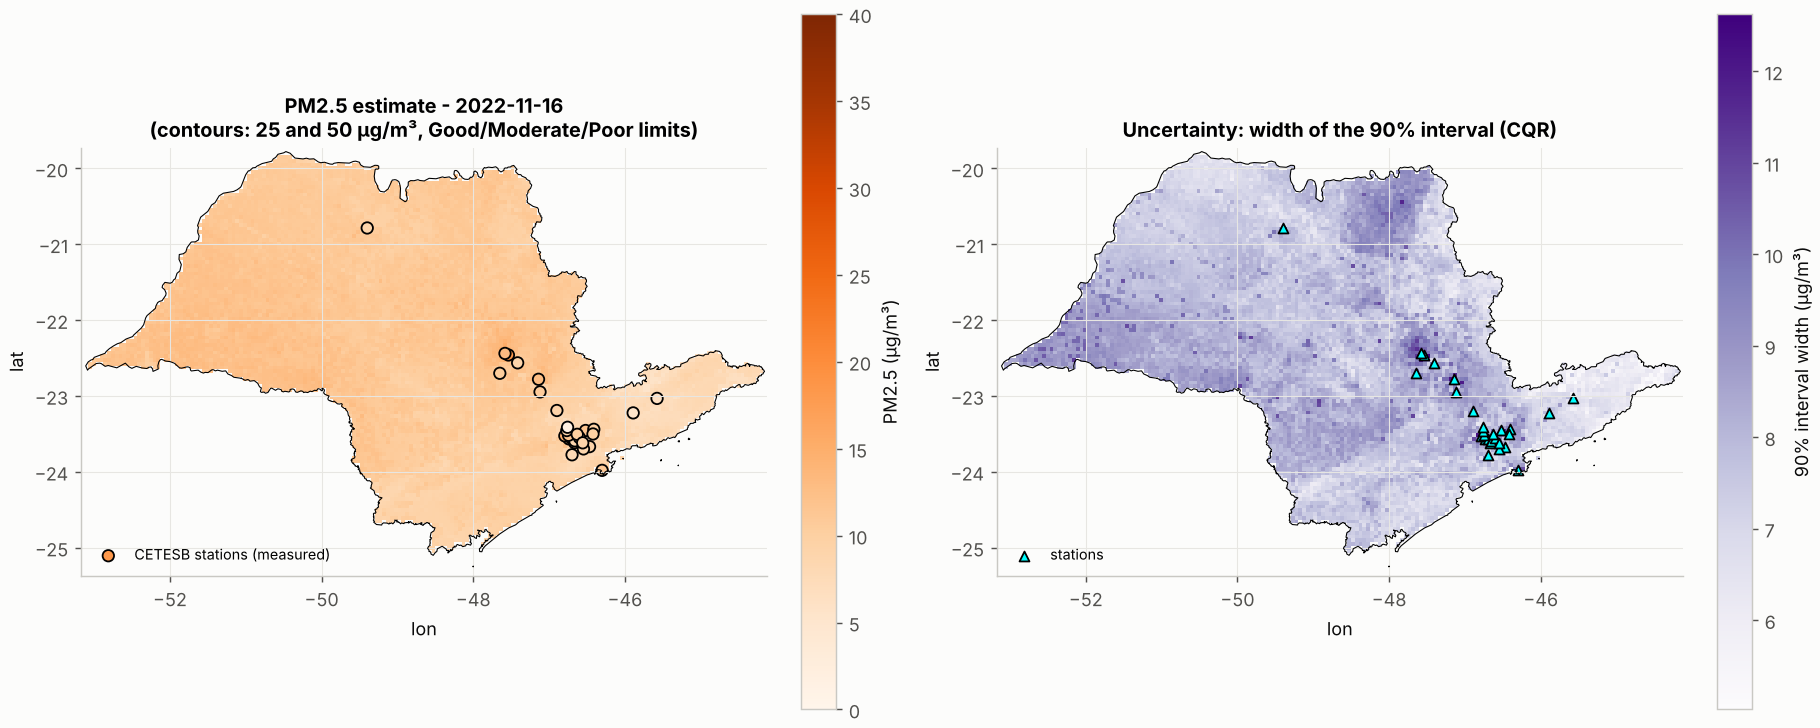

In [11]:
for p in sorted((ROOT/'reports/figures').glob('mapa_pm25_*.png')): display(Markdown(f'`{p.name}`')); fig(p.name)

## Interface: function/CLI/API for a coordinate and date (output keys in Portuguese)

In [12]:
from src.aq.predict import predict_one
print(json.dumps(predict_one(-23.4969, -47.4451, '2021-08-24', 0), ensure_ascii=False, indent=1))
print(json.dumps(predict_one(-23.4969, -47.4451, '2021-08-23', 1), ensure_ascii=False, indent=1))

{
 "lat": -23.4969,
 "lon": -47.4451,
 "data_referencia": "2021-08-24",
 "data_alvo": "2021-08-24",
 "horizonte_dias": 0,
 "pm25_ug_m3": 54.4,
 "intervalo_90": [
  32.6,
  85.9
 ],
 "faixa_iqar": "Ruim",
 "padrao_24h_vigente": {
  "norma": "Resolução CONAMA 491/2018, art. 4º, § 1º e Anexo I",
  "etapa": "PI-1",
  "valor": 60.0
 },
 "ultrapassa_padrao": false,
 "diagnostico": {
  "aod_disponivel": true,
  "aod_nivel_preenchimento": 0,
  "estacoes_usadas_idw": 8,
  "dist_estacao_mais_proxima_km": 65.4
 },
 "fonte": "modelo LightGBM + CQR; satélite GOES-16, ERA5, rede CETESB via OpenAQ",
 "feature_schema": "causal-spatial-aod-v2",
 "emissao": "fim do dia de referência; dados históricos, sem feed em tempo real"
}
{
 "lat": -23.4969,
 "lon": -47.4451,
 "data_referencia": "2021-08-23",
 "data_alvo": "2021-08-24",
 "horizonte_dias": 1,
 "pm25_ug_m3": 56.6,
 "intervalo_90": [
  27.7,
  92.8
 ],
 "faixa_iqar": "Ruim",
 "padrao_24h_vigente": {
  "norma": "Resolução CONAMA 491/2018, art. 4º, § 1º